# H1 · A clamped sense: inferring the hidden rate
*Step 2 of network-spectral-predictor · hidden information with a clamped sense · actual = generated world, nominal = prediction*

From here on only the angles are measured. Each pendulum has to infer its own rate from its clamped sense and its neighbours' messages, with step 1's maps frozen.

**Where we're at.** Step 2, first rung: hidden information. The rates are never measured again; each body's sense is clamped to its angle.

**Where the system is after the last experiments.** Step 1 closed with every body fully observed. The learned maps transfer across body counts and wirings, and the binding vertex tracks rewiring among all 256 wirings of a ring of 8 (E7).

**Where we want it.** Each body recovers its hidden rate from its angle alone, locally, about as well as a centralised optimal filter, so that step 1's machinery can run unchanged on what it infers.

**How this set moves it.** With step 1's maps frozen, four ways of turning measured angles into a full state are compared on a ring of 8: the plan's delay line; a clamped sense with fixed precision; the same with a precision that grows from a cold start; and a centralised Kalman filter. Learning comes in H2.

In [1]:
%config InlineBackend.figure_format = 'retina'
import sys
from pathlib import Path
import numpy as np
from IPython.display import display
STUDY = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(STUDY))
import figures as F
from nsp import config, graphs, sense, viz, world as W
F.setup()
cfg = F.cfg("h1")
world = config.world_from(cfg)
p = cfg["h1"]

In [2]:
F.ledger("h1")

**Configuration ledger**

| Setting | Value | Meaning |
| --- | --- | --- |
| `world.omega0` | 2.0 | a lone pendulum's frequency (rad/s) |
| `world.kappa` | 1.0 | spring stiffness ÷ inertia (1/s²) |
| `world.dt` | 0.05 | sampling step (s) |
| `world.d` | 1 | position coordinates per body (1 = planar) |
| `run.seeds` | [0, 1, 2] | seeds run (kept low on purpose) |
| `graph` | ring | how the springs are wired |
| `n` | 8 | number of bodies |
| `amplitude` | 0.1 | starting swing size (rad) |
| `p_on` | 0.7 | chance each spring is live in a run's wiring (known here) |
| `steps` | 400 | steps per run |
| `trials` | 10 | runs per seed and condition |
| `noise` | 0.01 | sense noise on angles, fraction of the swing |
| `noise_levels` | [0.001, 0.01, 0.05] | sense noise levels swept |
| `horizon` | 20 | how far ahead the nominal world predicts (steps) |
| `q_levels` | [1e-09, 1e-08, 1e-07, 1e-06, 1e-05] | rate noise the clamp allows for, (rad/s)² per step |
| `lambda_grid_max` | 8.0 | largest graph frequency plotted |
| `train_sizes` | [3, 5] | body counts step 1's maps were learned on |
| `train_graphs` | ['path', 'ring'] | graphs step 1's maps were learned on |
| `train_patterns` | 3 | random gate patterns per training graph |
| `train_trajectories` | 10 | trajectories per training graph |
| `train_steps` | 200 | steps per training trajectory |

## The question

Each body $v$ now senses only its angle, with noise of standard deviation $s$ (1% of the swing):

$$\underbrace{y_v(t)}_{\text{clamped sense}}=\underbrace{c}_{[1,\;0]}\;\underbrace{x_v(t)}_{(\theta_v,\ \dot\theta_v)}+\varepsilon_v(t),\qquad\varepsilon_v\sim\mathcal N(0,s^2)$$

**The delay line** (the plan's first memory) reads the rate off the last two readings. The angle rows of the step give $y(t)=A_{\theta\theta}\,y(t-1)+A_{\theta\dot\theta}\,\dot\theta(t-1)$, so

$$\hat{\dot\theta}(t-1)=A_{\theta\dot\theta}^{-1}\big(y(t)-A_{\theta\theta}\,y(t-1)\big)\;\approx\;\frac{y(t)-y(t-1)}{\Delta t}\qquad\Longrightarrow\qquad\operatorname{sd}\big(\hat{\dot\theta}\big)\approx\frac{\sqrt2\,s}{\Delta t}$$

Relative to the rate scale $a\,\omega_0$ (swing $a$ = 0.1 rad), that is $\sqrt2\times0.001/(0.05\times0.2)\approx14\%$, and it never improves: every estimate uses only two readings.

**The clamped sense.** Each body first predicts with step 1's maps and its neighbours' messages, then relaxes on an energy that weighs its clamped sense against its own prediction:

$$\underbrace{\hat x^-_v(t)}_{\text{prediction}}=K\hat x_v(t-1)-M\sum_u g_{uv}\big(\hat x_v(t-1)-\hat x_u(t-1)\big)$$

$$E_v(x)=\underbrace{\frac{\big(y_v-c\,x\big)^2}{2s^2}}_{\text{sense error (sense precision }1/s^2)}+\underbrace{\tfrac12\big(x-\hat x^-_v\big)^{\!\top}\,\Pi^{-1}\big(x-\hat x^-_v\big)}_{\text{prediction error (prior precision }\Pi^{-1})},\qquad\frac{dx}{d\tau}=-\nabla E_v$$

The relaxation settles where the gradient vanishes, which is a gain $k$ on the angle error:

$$\hat x_v(t)=\hat x^-_v(t)+\underbrace{\frac{\Pi c^\top}{c\,\Pi c^\top+s^2}}_{k\;(2\times1)}\big(y_v(t)-c\,\hat x^-_v(t)\big)$$

The angle error corrects the hidden rate too, through the off-diagonal of $\Pi$. With **fixed precision**, $\Pi$ is the lone body's steady state, which follows from the Riccati equation once we say how much unmodelled force to expect ($q$, rate variance per step). With **growing precision**, each body starts unsure ($\Pi$ large: trust the sense) and runs its own $2\times2$ Riccati recursion, so its gain shrinks as it becomes sure. Both are local: no body sees another body's covariance. The **Kalman filter** shares the full $16\times16$ covariance; it is the optimal linear reference under the same assumptions.

**Stability, one graph frequency at a time.** The error obeys $e(t)=\big(I-(I_8\otimes k)\,C\big)P\,e(t-1)$, and the spectrum identity splits it:

$$\operatorname{spec}\Big(\big(I-(I_8\otimes k)C\big)\big(I_8\otimes K-L\otimes M\big)\Big)=\bigcup_k\operatorname{spec}\Big(\underbrace{(I-kc)\,(K-\lambda_kM)}_{2\times2}\Big)$$

so the slowest graph mode's spectral radius $\rho_{\max}$ predicts the convergence rate.

**Prediction.** The delay line's rate error is about 14% at 1% noise and does not shrink. The clamped sense averages over time. With growing precision it comes within 1.5× of the Kalman filter in both error and settling time, and its convergence follows $\rho_{\max}^t$.
**Pass if** the delay line is within 10% of $\sqrt2\,s/(\Delta t\,a\,\omega_0)$; the growing-precision clamp is within 1.5× of the Kalman filter in steady rate error and in settling time, and at least 10× better than the delay line; and the measured convergence rate is within 10% of $\log\rho_{\max}$.

In [3]:
runs = F.ensure_results("h1")

h1: 3 seeds loaded (code 6c136f0, run 2026-11-25T21:56:39+00:00)


## One body's step

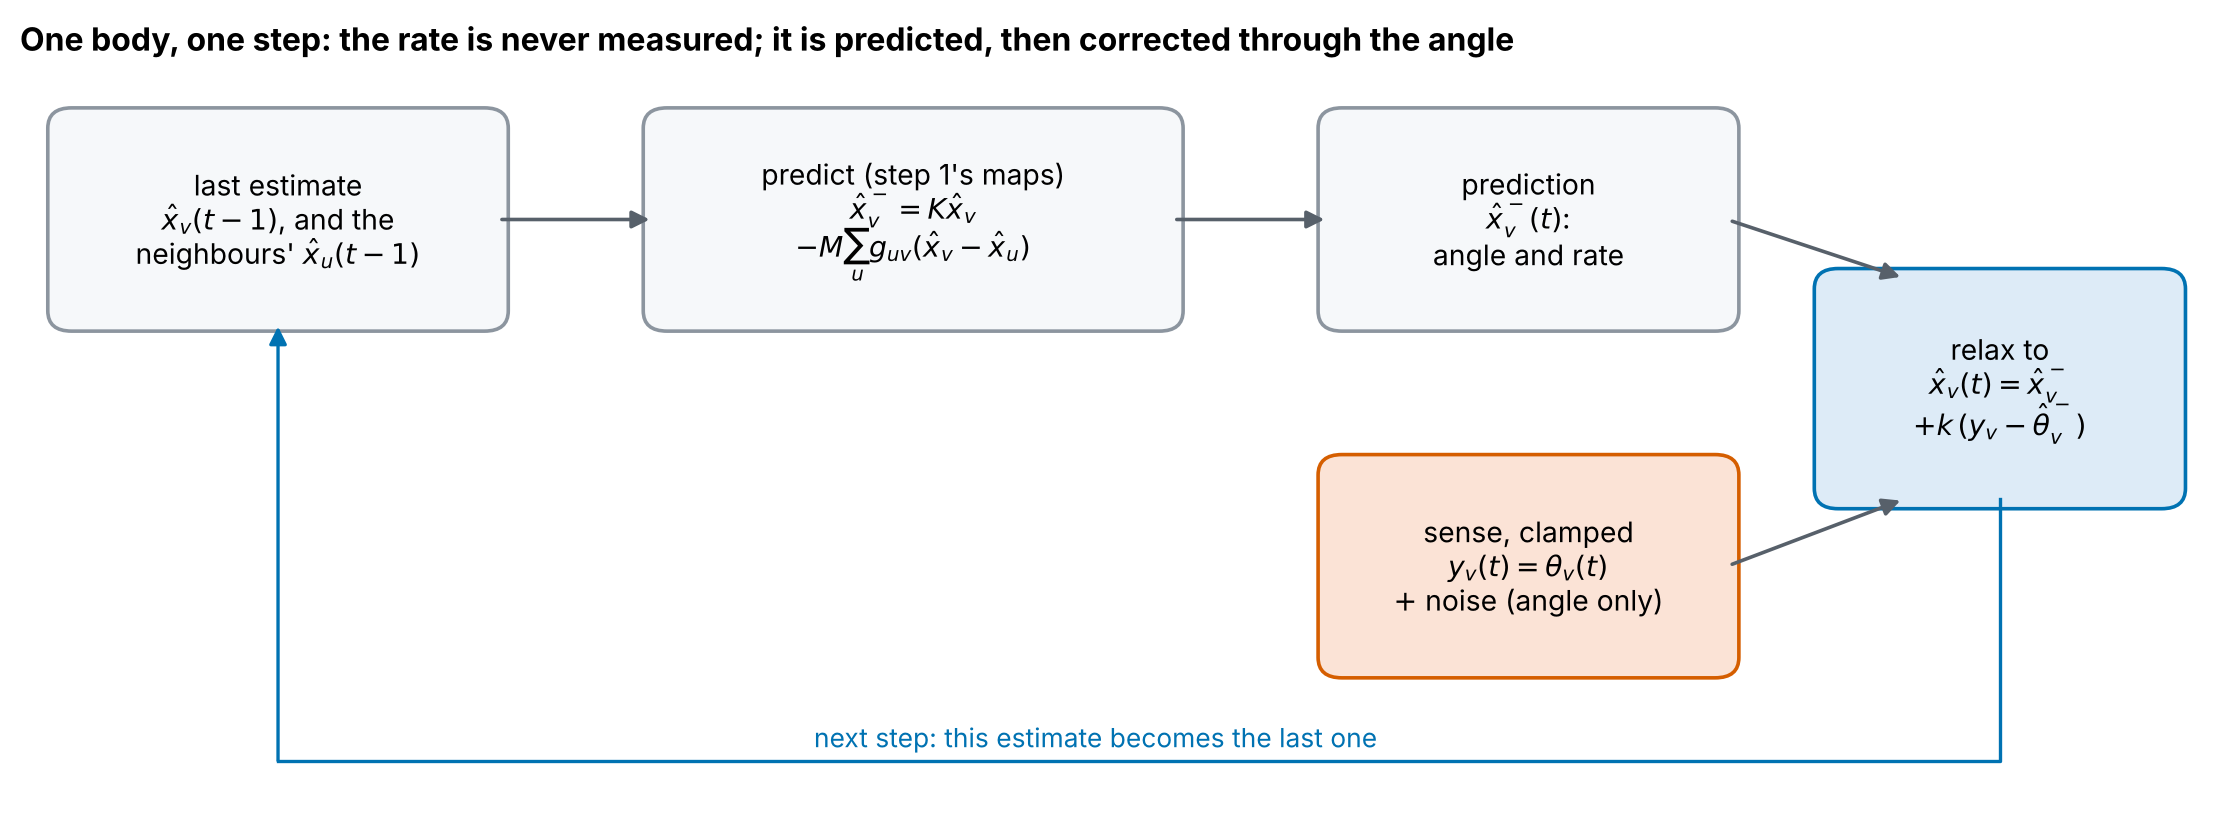

In [4]:
F.schematic();

## Nominal vs actual: one second ahead

The nominal world is the prediction made **one second earlier** from each method's estimated state, using step 1's maps. The delay line starts from a noisy rate, so its predictions wander; the clamped sense starts from a rate it has averaged. Press **Play** to watch at real speed, or drag the slider. Actual bobs are filled, nominal bobs are hollow, and the whisker between them is the deviation, magnified (pick the factor) and coloured against the tolerance. The trace underneath is the largest deviation over time.

In [5]:
a = runs[0]["arrays"]
tol = 0.01 * p["amplitude"]
ring = graphs.ring(p["n"])
k = p["horizon"]  # the players start one second in, once a one-second-old prediction exists
for m, label in (("delay", "Delay line"), ("precision", "Clamped sense, growing precision")):
    display(viz.player(a["theta_act"][k:], a[f"theta_nom_{m}"][k:], ring, a["gates"], dt=world.dt, tol=tol,
                       title=f"{label}: the world as predicted one second earlier",
                       subtitle="Only angles measured (1% noise); the rates are inferred. Time starts 1 s into the run. "
                                "Tolerance: 1% of the 0.1 rad swing."))

## The hidden rate, inferred

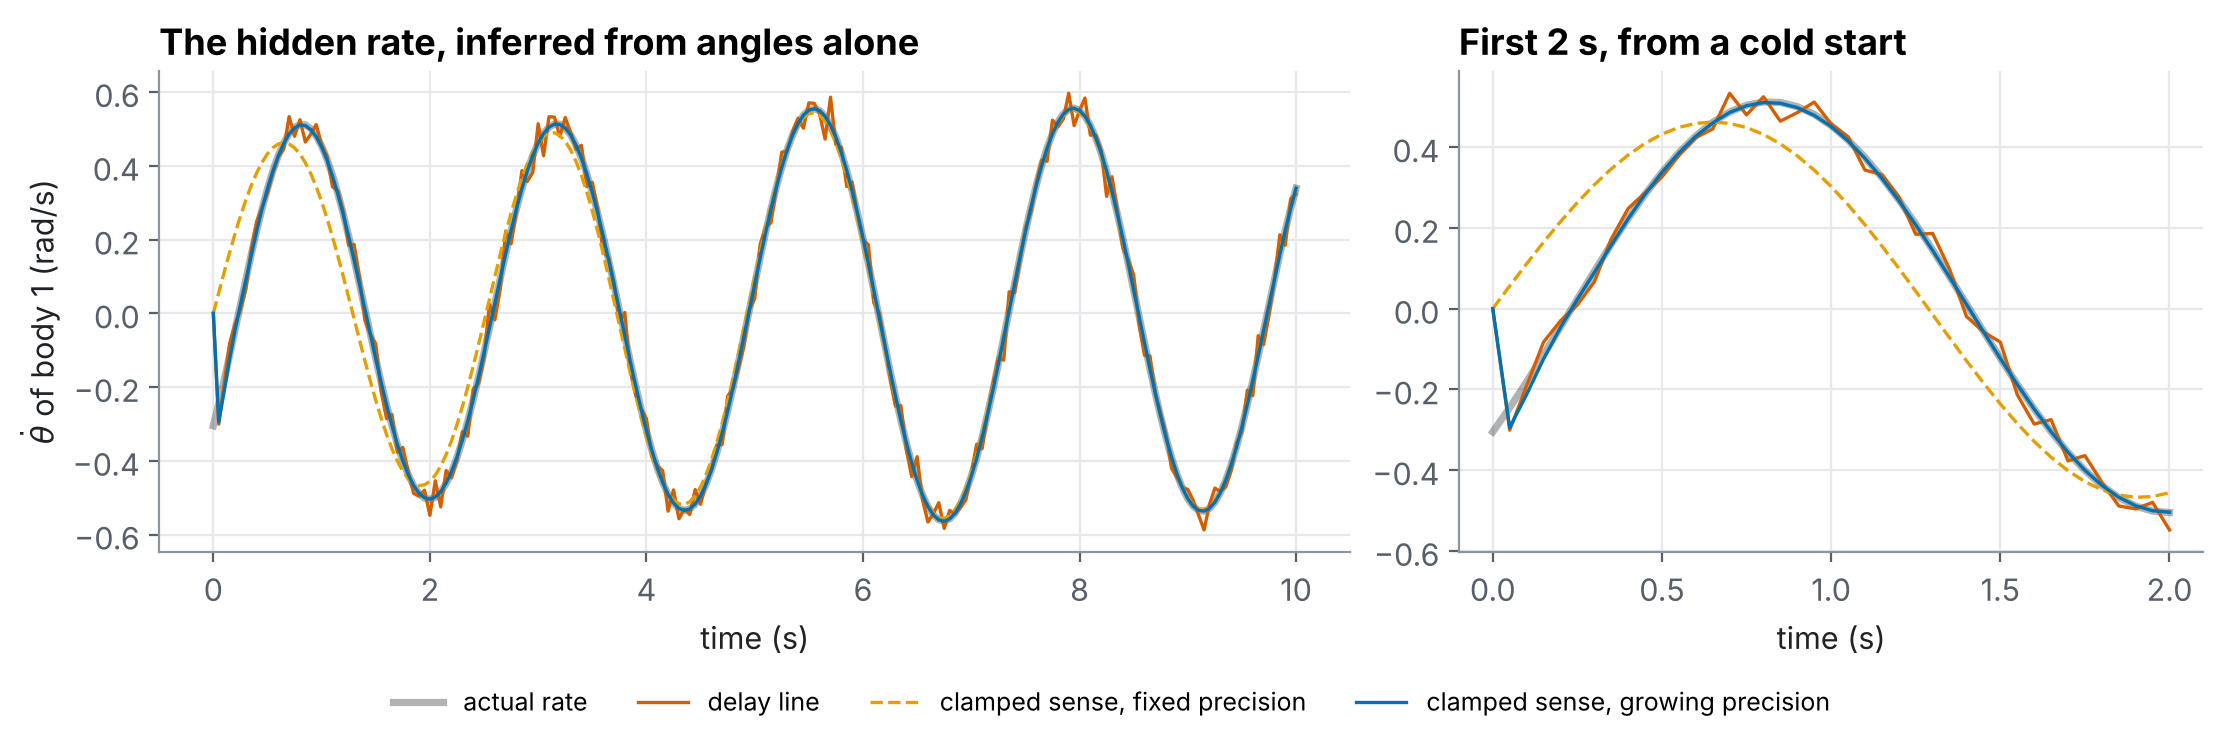

In [6]:
F.rate_trace(runs[0], world);

## How fast and how well

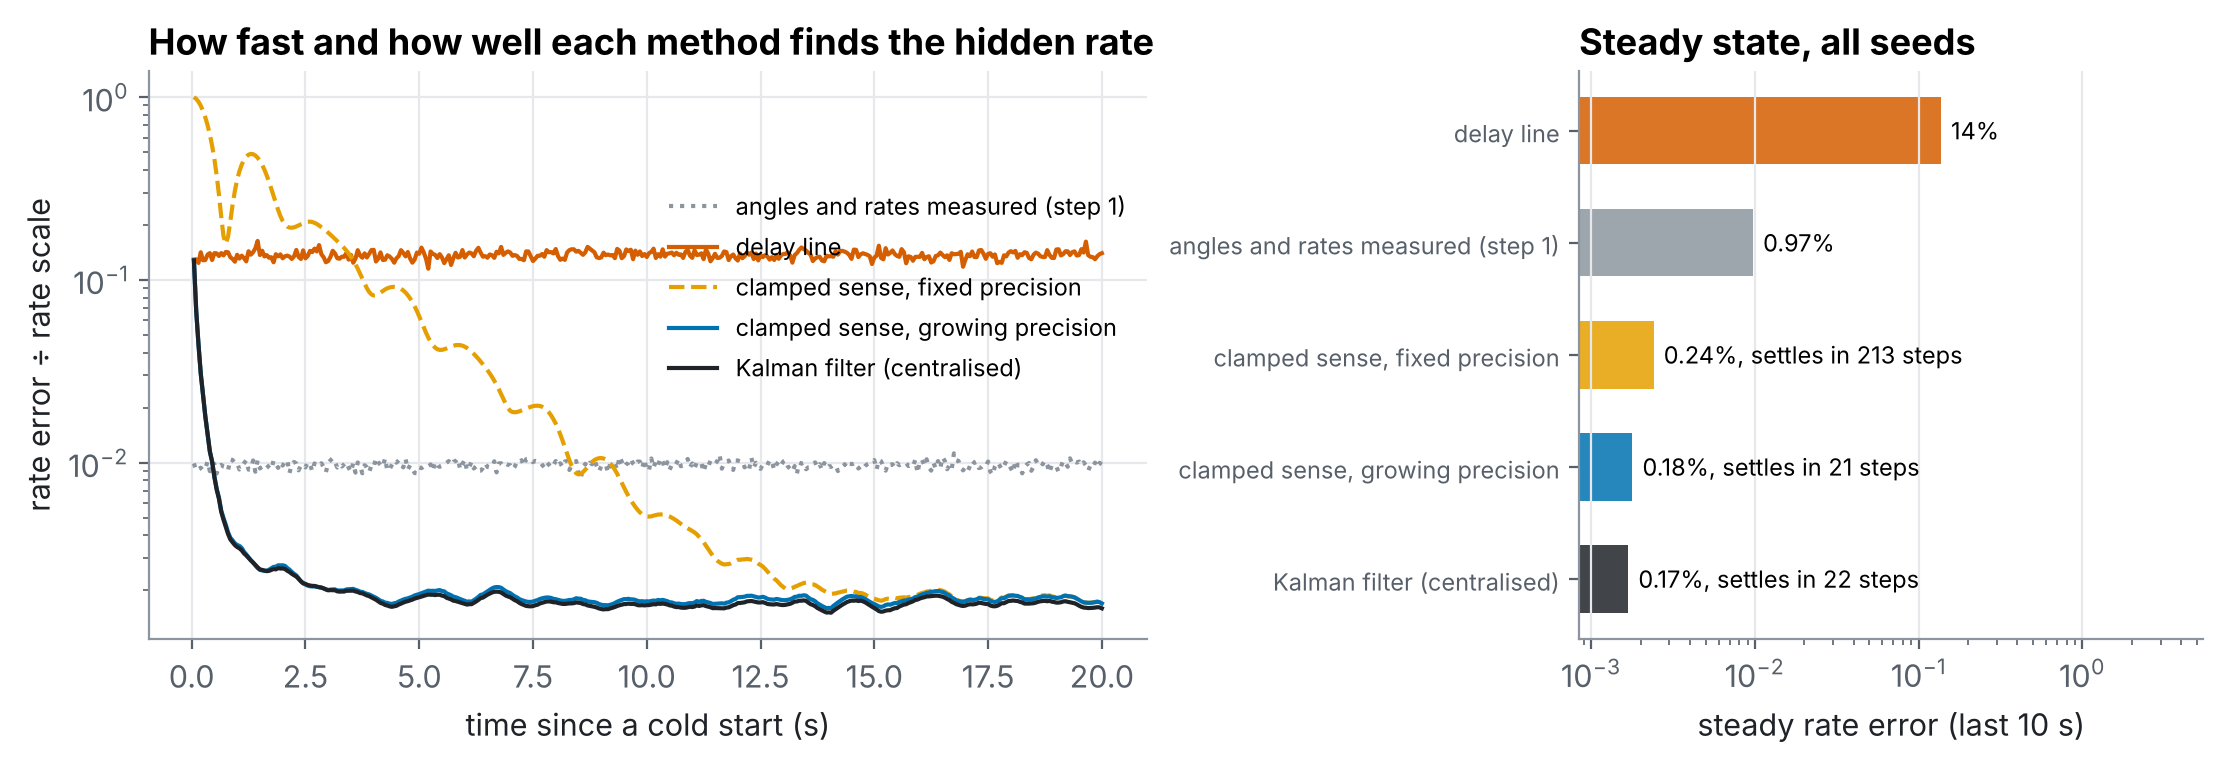

In [7]:
F.convergence(runs, world);

In [8]:
mm = [r["metrics"] for r in runs]
st = lambda m, key="rate": [x["steady"][m][key] for x in mm]
F.say(f"The delay line's rate error is {F.spread([100 * v for v in st('delay')])}% of the rate scale, as predicted from "
      f"differencing noisy angles, and it stays there. The clamped sense with growing precision reaches "
      f"{F.spread([100 * v for v in st('precision')])}% and settles in {F.spread(st('precision', 'settle'))} steps; the "
      f"centralised Kalman filter reaches {F.spread([100 * v for v in st('kalman')])}% in {F.spread(st('kalman', 'settle'))} "
      f"steps. Measuring the rates directly, as in step 1, gives {F.spread([100 * v for v in st('full')])}%: inferring the "
      f"rate beats measuring it, because the inference averages over time. With a fixed precision the clamp is as "
      f"accurate in the end ({F.spread([100 * v for v in st('clamped')])}%) but needs {F.spread(st('clamped', 'settle'))} "
      "steps to get there.")

> **Finding.** The delay line's rate error is 13.7 (13.6 to 13.8)% of the rate scale, as predicted from differencing noisy angles, and it stays there. The clamped sense with growing precision reaches 0.178 (0.177 to 0.18)% and settles in 21 (18 to 23) steps; the centralised Kalman filter reaches 0.168 (0.165 to 0.171)% in 21.7 (19 to 24) steps. Measuring the rates directly, as in step 1, gives 0.973 (0.972 to 0.976)%: inferring the rate beats measuring it, because the inference averages over time. With a fixed precision the clamp is as accurate in the end (0.241 (0.239 to 0.242)%) but needs 213 (208 to 217) steps to get there.

## One check per graph frequency

The spectral radius is the same at every graph frequency. For a $2\times2$ map with a complex pair of eigenvalues, $|\mu|^2=\det$, and

$$\rho=\sqrt{\det\big((I-kc)(K-\lambda M)\big)}=\sqrt{\underbrace{(1-k_\theta)}_{\det(I-kc)}\;\underbrace{\det(K-\lambda M)}_{\approx\,1\text{: the step nearly preserves area}}}\;\approx\;\sqrt{1-k_\theta}$$

so every graph mode converges at the rate set by the angle gain $k_\theta$ alone, as long as its eigenvalues stay complex.

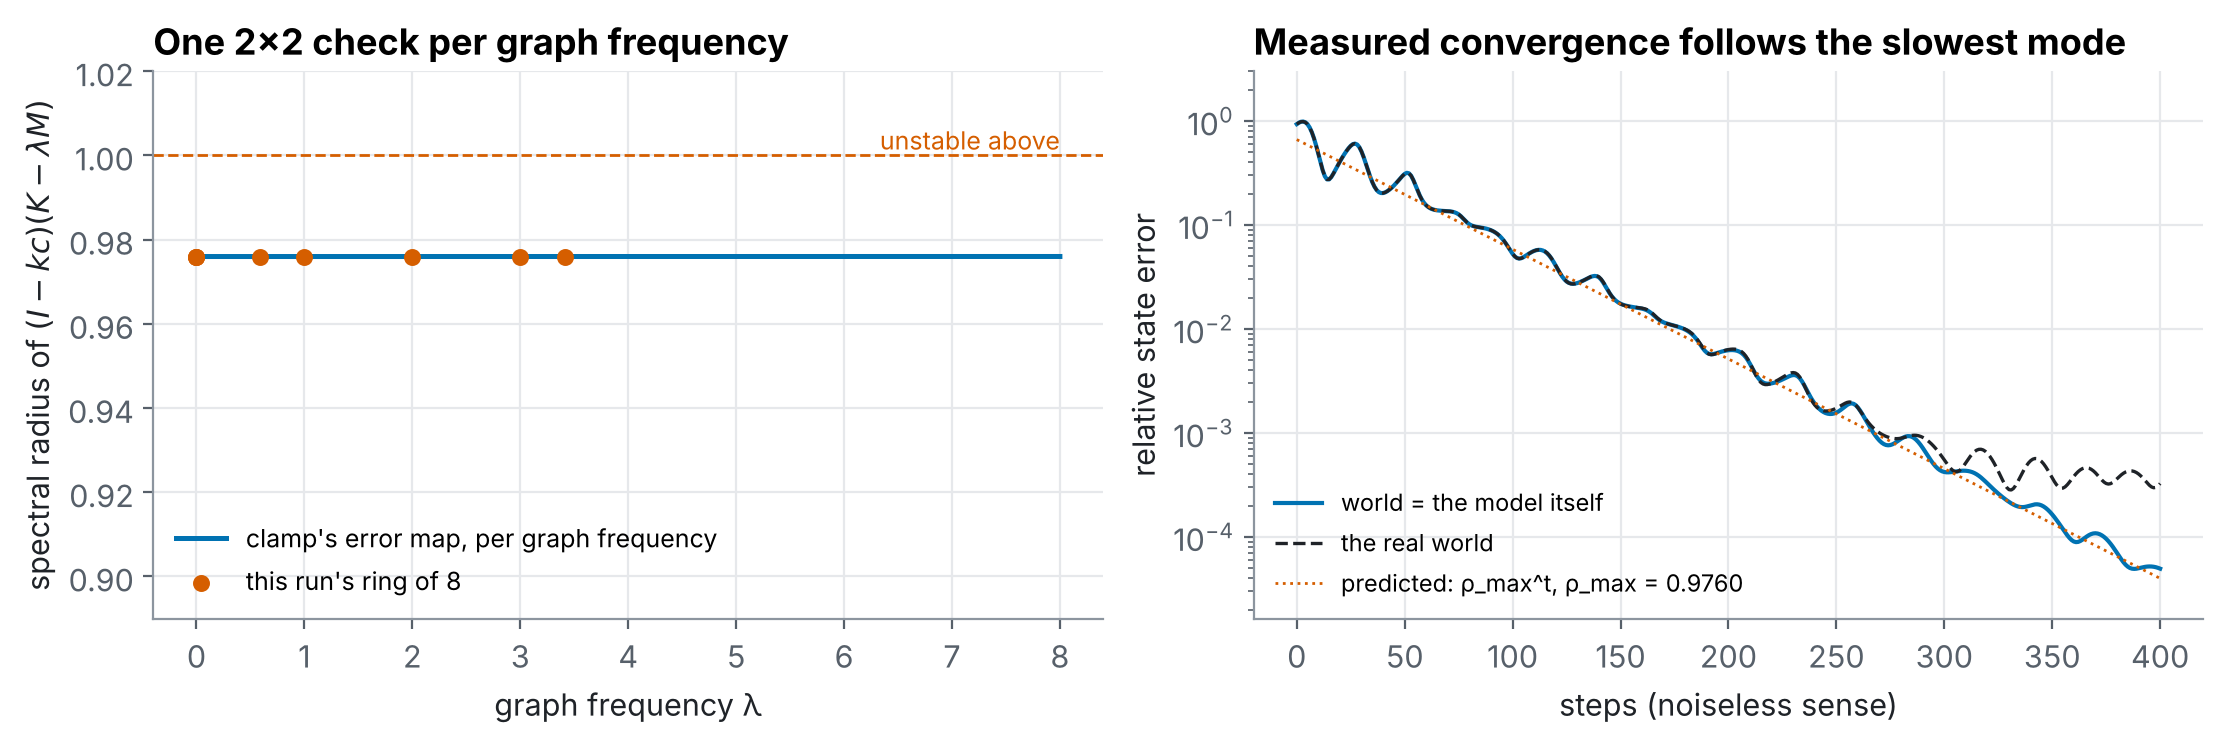

In [9]:
F.modes(runs[0]);

In [10]:
F.say(f"The slowest mode predicts a decay of {F.spread([x['predicted_slope'] for x in mm])} per step (log scale). "
      f"Measured on a noiseless sense, the error decays at {F.spread([x['clean_slope']['model'] for x in mm])} when the world "
      f"is the model itself, and at {F.spread([x['clean_slope']['world'] for x in mm])} in the real world, where the "
      "two-hop term that step 1's maps cannot hold keeps feeding a little error in and sets a floor.")

> **Finding.** The slowest mode predicts a decay of −0.0243 (−0.0243 to −0.0243) per step (log scale). Measured on a noiseless sense, the error decays at −0.0243 (−0.0245 to −0.0242) when the world is the model itself, and at −0.0238 (−0.0242 to −0.0235) in the real world, where the two-hop term that step 1's maps cannot hold keeps feeding a little error in and sets a floor.

## Inside one step: relaxation

What the gain formula summarises: starting from the prediction, the body descends its energy. The sense pulls the angle at once; the prior's covariance then carries part of that correction into the hidden rate. This inner loop is the "relax toward equilibrium" half of the learning scheme; H2 adds the other half, learning from what the relaxation could not explain.

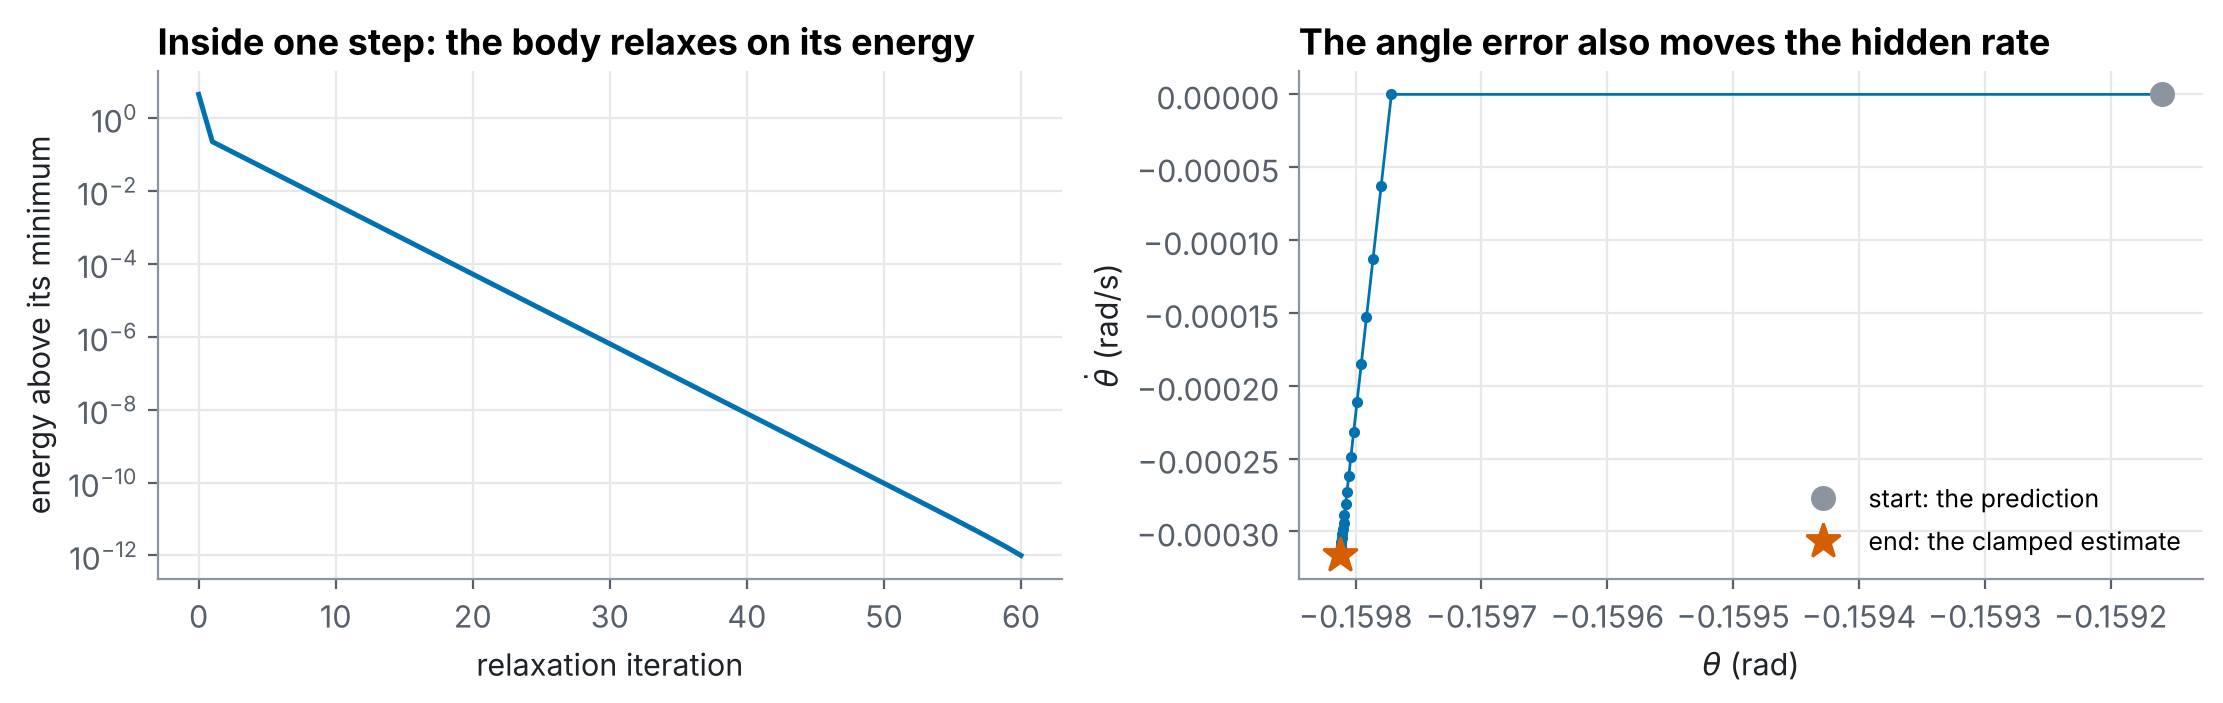

In [11]:
F.relaxation(runs[0]);

## Speed, accuracy and noise

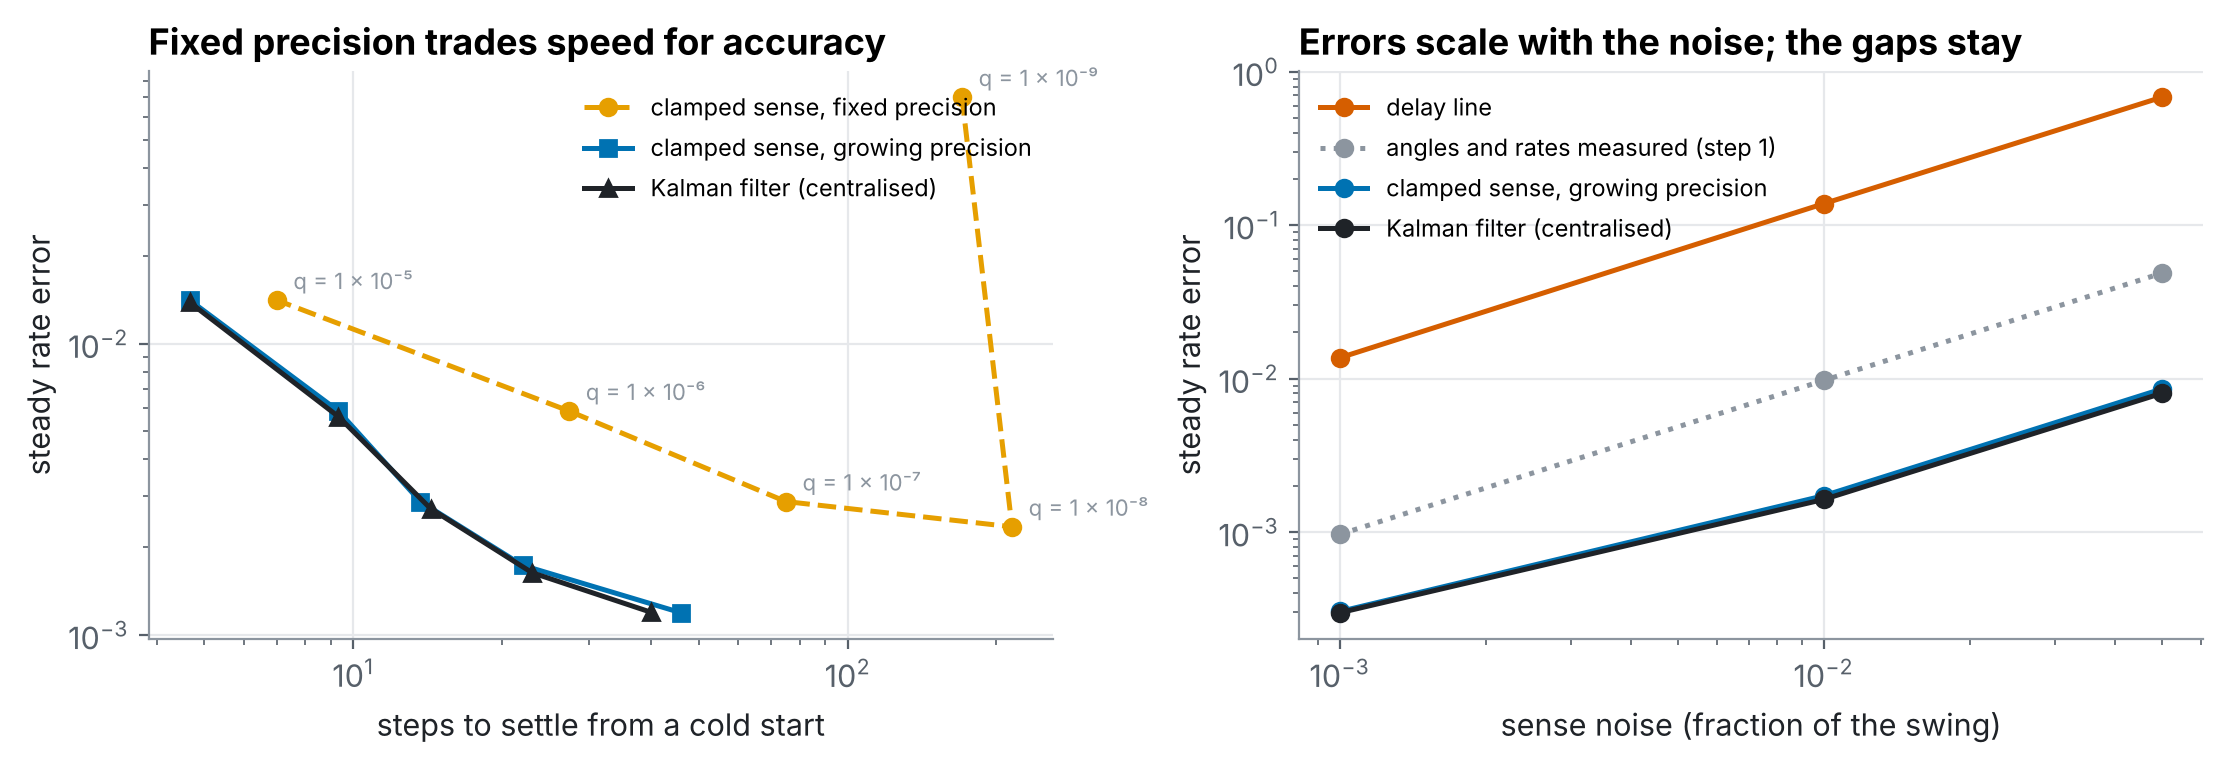

In [12]:
F.tradeoff(runs);

In [13]:
bq = lambda i, m, key: float(np.mean([x["by_q"][i]["steady"][m][key] for x in mm]))
qs = [c["q"] for c in mm[0]["by_q"]]
bn = lambda m: np.array([np.mean([x["by_noise"][i]["steady"][m]["rate"] for x in mm]) for i in range(len(mm[0]["by_noise"]))])
vs_delay, vs_full = bn("delay") / bn("precision"), bn("full") / bn("precision")
F.say(f"With a fixed precision, allowing more unmodelled force ($q$ from {viz.fmt(qs[1], 1)} to {viz.fmt(qs[-1], 1)}) cuts the "
      f"settling time from {bq(1, 'clamped', 'settle'):.0f} to {bq(len(qs) - 1, 'clamped', 'settle'):.0f} steps but raises "
      f"the steady error from {viz.pct(bq(1, 'clamped', 'rate'))} to {viz.pct(bq(len(qs) - 1, 'clamped', 'rate'))}. A growing "
      "precision settles fast at every $q$ and tracks the Kalman filter, so $q$ only sets the final accuracy. Across the "
      f"noise levels, the clamped sense with growing precision is {vs_delay.min():.0f}× to {vs_delay.max():.0f}× better "
      f"than the delay line and {vs_full.min():.1f}× to {vs_full.max():.1f}× better than measuring the rates.")

> **Finding.** With a fixed precision, allowing more unmodelled force ($q$ from 1 × 10⁻⁸ to 1 × 10⁻⁵) cuts the settling time from 215 to 7 steps but raises the steady error from 0.23% to 1.4%. A growing precision settles fast at every $q$ and tracks the Kalman filter, so $q$ only sets the final accuracy. Across the noise levels, the clamped sense with growing precision is 45× to 80× better than the delay line and 3.2× to 5.7× better than measuring the rates.

## Inspection report

In [14]:
mean = lambda xs: float(np.mean(xs))
s, a_, om = p["noise"] * p["amplitude"], p["amplitude"], world.omega0
pred_delay = np.sqrt(2) * s / (world.dt * a_ * om)
ratio_err = mean(st("precision")) / mean(st("kalman"))
ratio_set = mean(st("precision", "settle")) / mean(st("kalman", "settle"))
gain = mean(st("delay")) / mean(st("precision"))
slope_m, slope_p = mean([x["clean_slope"]["model"] for x in mm]), mean([x["predicted_slope"] for x in mm])
viz.inspection_report([
    {"characteristic": "Delay line rate error (fraction of the rate scale)", "nominal": pred_delay, "actual": mean(st("delay")),
     "deviation": mean(st("delay")) - pred_delay, "tolerance": 0.1 * pred_delay},
    {"characteristic": "Growing-precision clamp ÷ Kalman, steady rate error", "nominal": ratio_err, "actual": 1.0,
     "deviation": ratio_err - 1, "tolerance": 0.5},
    {"characteristic": "Growing-precision clamp ÷ Kalman, settling time", "nominal": ratio_set, "actual": 1.0,
     "deviation": ratio_set - 1, "tolerance": 0.5},
    {"characteristic": "Delay line ÷ growing-precision clamp, rate error", "nominal": gain, "tolerance": "≥ 10×",
     "status": "in" if gain >= 10 else "out"},
    {"characteristic": "Convergence per step, log scale (model's own world)", "nominal": slope_p, "actual": slope_m,
     "deviation": slope_m - slope_p, "tolerance": 0.1 * abs(slope_p)},
], title="The clamped sense, means over seeds (1% noise, ring of 8, wiring known)")

**The clamped sense, means over seeds (1% noise, ring of 8, wiring known)**

| Characteristic | Nominal (predicted) | Actual (generated) | Deviation | Tolerance | Status |
| --- | --- | --- | --- | --- | --- |
| Delay line rate error (fraction of the rate scale) | 0.1414 | 0.1368 | −0.004596 | ±0.01414 | ✓ **in** |
| Growing-precision clamp ÷ Kalman, steady rate error | 1.059 | 1 | 0.05914 | ±0.5 | ✓ **in** |
| Growing-precision clamp ÷ Kalman, settling time | 0.9692 | 1 | −0.03077 | ±0.5 | ✓ **in** |
| Delay line ÷ growing-precision clamp, rate error | 76.68 | — | — | ≥ 10× | ✓ **in** |
| Convergence per step, log scale (model's own world) | −0.02429 | −0.02435 | −5.228 × 10⁻⁵ | ±0.002429 | ✓ **in** |

## Next: learning with a clamped sense (H2)

H1 kept step 1's maps frozen. H2 learns them from angles alone, which raises one question to settle first. When only $\theta$ is sensed, any change of hidden coordinates that leaves the angle alone predicts exactly the same angles:

$$K\to TKT^{-1},\qquad M\to TMT^{-1},\qquad c\,T^{-1}=c\qquad\text{for every}\qquad T=\begin{bmatrix}1&0\\ \alpha&\beta\end{bmatrix},\ \beta\neq0$$

So the learned hidden coordinate can be any mix $\alpha\theta+\beta\dot\theta$, and reading $\omega_0^2$ and $\kappa$ off single entries of $K$ and $M$, as E1 did, would break. Spectral readouts survive the change of coordinates: $\omega_0=|\arg\operatorname{eig}K|/\Delta t$, and $\kappa$ from $\operatorname{eig}(K-\lambda M)$ at known $\lambda$.

Three choices are yours before H2 is built:
1. **The learning rule.** Your scheme: relax to equilibrium (as above), then learn from the gap between the optimal energy and the energy that inference alone reached. Here the sense is the clamp.
2. **Which precisions are learned.** The sense precision $1/s^2$, the prior precision $\Pi^{-1}$, or both. H1 fixed $s$ and derived $\Pi$.
3. **The hidden coordinate.** Accept the freedom and read physics spectrally, or pin it, for example by declaring the second coordinate to be the rate.

## Log

In [15]:
F.log(runs)

| Seed | Code version | Run at (UTC) | Python | NumPy | SciPy |
| --- | --- | --- | --- | --- | --- |
| 0 | `6c136f0` | 2026-11-25T21:56:39+00:00 | 3.13.18 | 2.5.3 | 1.18.1 |
| 1 | `6c136f0` | 2026-11-25T21:56:39+00:00 | 3.13.18 | 2.5.3 | 1.18.1 |
| 2 | `6c136f0` | 2026-11-25T21:56:41+00:00 | 3.13.18 | 2.5.3 | 1.18.1 |